# 01. Обзор данных

Цель: понять, **какие данные у нас есть и чем они опасны для модели**, до того как строить модели.
Под каждым графиком — вывод в формате «что видим → что значит для модели».

Источники: WDI (готов), AidData GCDF 3.0 и BACI (будут добавлены).

In [2]:
import sys
from pathlib import Path

# Ноутбук лежит в notebooks/, а пакет src — в корне проекта
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.etl.wdi import load_wdi, to_wide

sns.set_theme(style="white", font_scale=0.9)
long = load_wdi()
wide = to_wide(long)
long.shape, wide.shape

((9504, 4), (1188, 10))

## 1. Карта пропусков: страна × год

**Вопрос:** где пропуски — разбросаны случайно или собраны в отдельных странах и годах?

Цвет клетки — сколько из 7 показателей пусто в этой стране в этом году
(население заполнено всегда, поэтому его не считаем). Страны отсортированы по общему числу пропусков:
самые «дырявые» — сверху.

Как читать:
- **горизонтальная тёмная полоса** — страна плохо покрыта весь период;
- **вертикальная полоса** — проблема года (например, последние годы ещё не обновлены);
- **тёмный угол** — у страны нет данных в начале или в конце периода (новая страна, война).

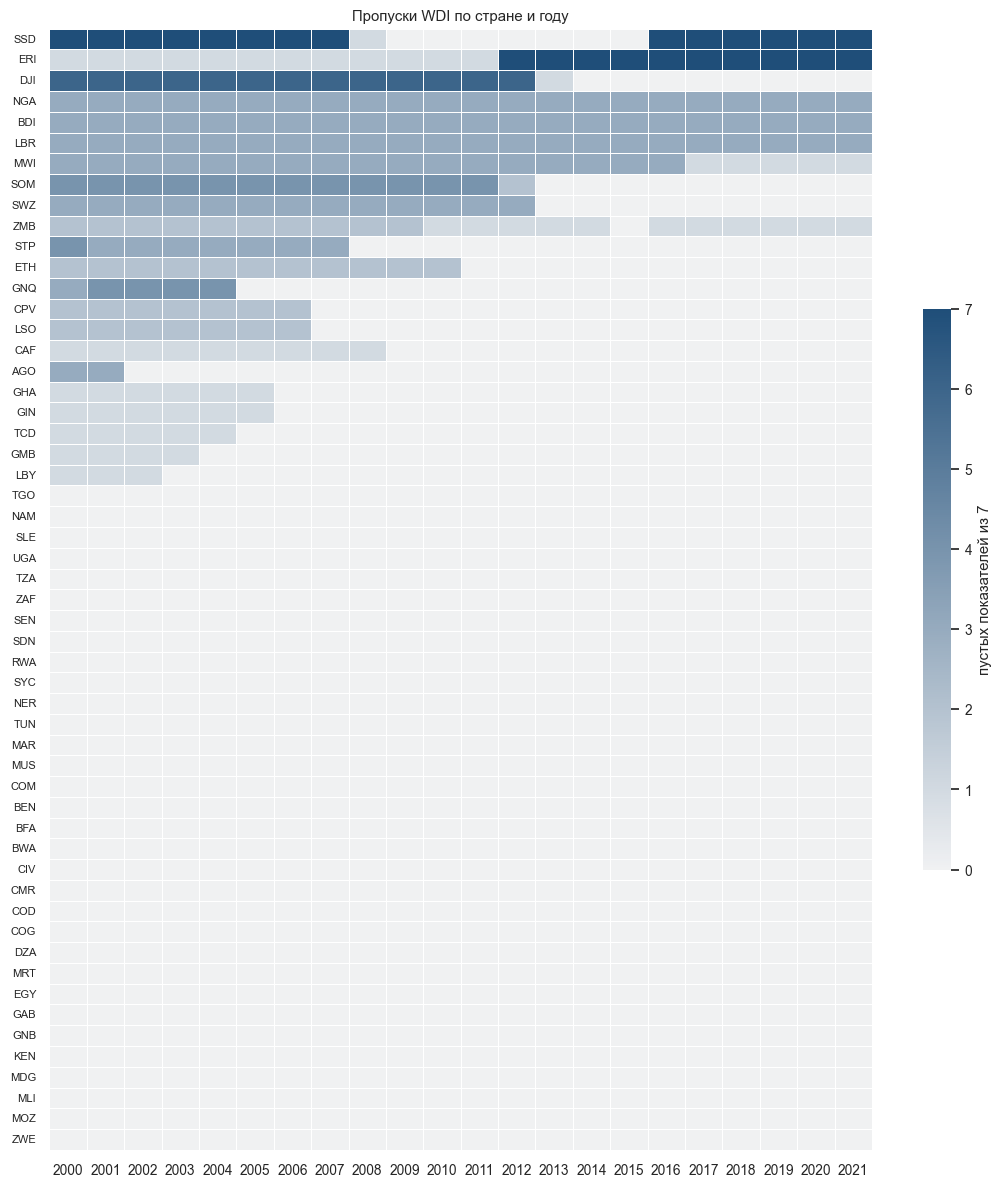

In [3]:
cols = [c for c in wide.columns if c not in ("iso3", "year", "pop")]
n_missing = (
    wide.assign(n_missing=wide[cols].isna().sum(axis=1))
        .pivot(index="iso3", columns="year", values="n_missing")
)
n_missing = n_missing.loc[n_missing.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 12))
sns.heatmap(
    n_missing, ax=ax,
    cmap=sns.light_palette("#1f4e79", as_cmap=True),  # один оттенок: светлый = полно, тёмный = пусто
    vmin=0, vmax=len(cols), linewidths=0.5, linecolor="white",
    cbar_kws={"label": f"пустых показателей из {len(cols)}", "shrink": 0.5},
)
ax.set(title="Пропуски WDI по стране и году", xlabel="", ylabel="")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

Сводка: доля пустых страна-лет по каждому показателю и страны, где показатель пуст весь период.

In [4]:
share = wide[cols].isna().mean().sort_values(ascending=False).rename("доля пропусков")
always_empty = {c: sorted(wide.loc[wide[c].isna()].groupby("iso3").size().loc[lambda s: s == 22].index)
                for c in cols}
pd.DataFrame({"доля пропусков": share.round(3),
              "пусто все 22 года": pd.Series(always_empty)})

,доля пропусков,пусто все 22 года
exports,0.210,"[BDI, ERI, LBR, MWI, NGA]"
exports_pct,0.150,"[BDI, LBR, NGA]"
gdi,0.155,"[BDI, LBR, NGA]"
gdp,0.031,[]
gdp_pc,0.031,[]
growth,0.033,[]
rents,0.035,[]


### Вывод

*Видим что:* У SSD есть большой пропуск до 2008 и после 2016 и у ERI после 2012 отсутсвуют показания. 
NGA / LPR / MWI / LBR равномерно пропущены значения в большой массе. Мы видим что эти значения дают пустые exports / exports_pct / gdi

*Что значит для модели:* пропуски MNAR, связаны с нестабильностью, поэтому выбрасывание строк с NaN смещает выборку в сторону стабильных стран. Направление смещения эффекта заранее неизвестно (выпадает и Нигерия — крупный получатель кредитов),проверим после AidData. Каждая переменная в модели меняет выборку, поэтому: основной исход — log(gdp_pc) (покрытие 97%); 
экспорт — из BACI; gdi не берём в контроль (выбрасывает NGA/BDI/LBR и является медиатором). В робастности — сравнить     
результат на сбалансированной подвыборке.